# Lab 3.7 · Transformers and Diffusers

**15–20 minutes · CPU**

Follow the [lab guide](README.md) for setup. Run the setup cell, make a prediction for each exercise, replace each `return None`, and run its check.

A Transformers configuration gives the model's shape contract. A causal LM takes token IDs and produces one vector of vocabulary logits per position. To choose a next token greedily, take argmax over the last position. Diffusers exposes another useful contract: a scheduler consumes the current sample, timestep, and model prediction, and produces the sample for the next step.

Use a randomly initialized tiny GPT-2 to inspect real output shapes and a Diffusers DDIM scheduler with a supplied zero predictor to inspect the loop. The components are configured locally. Meaningful text or image quality requires trained weights and a real denoiser.

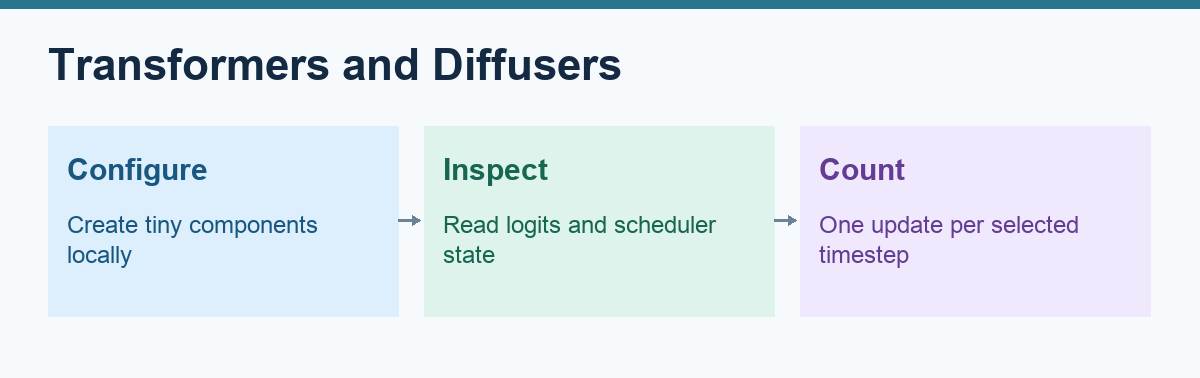

## Exercise map

| Exercise | What you will do | What to look for |
| --- | --- | --- |
| 1. Inspect causal-LM output | Run the model with input_ids under inference mode. Return the logits shape and a list of greedy next-token IDs, one per batch row. | The last dimension is tied to vocabulary size. Choosing the last position preserves one candidate per input sequence. |
| 2. Follow scheduler updates | Use set_timesteps(steps). For every timestep, call scheduler.step with a zero prediction of the same shape and the current sample. Feed prev_sample back into the next call. Return the final sample and list of timestep integers. | The scheduler controls the evaluation sequence. A real pipeline would supply a learned denoiser prediction at each step. |

In [ ]:
import torch
from transformers import GPT2Config, GPT2LMHeadModel
from diffusers import DDIMScheduler

torch.manual_seed(7)
config = GPT2Config(vocab_size=16, n_positions=16, n_embd=8, n_layer=1, n_head=2)
model = GPT2LMHeadModel(config).eval()
ids = torch.tensor([[1, 3, 5], [2, 4, 6]])
scheduler = DDIMScheduler(num_train_timesteps=20, clip_sample=False)
sample = torch.randn(1, 1, 4, 4)

## Exercise 1. Inspect causal-LM output

Run the model with input_ids under inference mode. Return the logits shape and a list of greedy next-token IDs, one per batch row.

In [ ]:
def inspect_logits(model, ids):
    return None

In [ ]:
result = inspect_logits(model, ids)
if result is not None:
    shape, predicted = result
    assert shape == (2, 3, config.vocab_size)
    with torch.inference_mode():
        expected = model(input_ids=ids).logits[:, -1].argmax(-1).tolist()
    assert predicted == expected
    print("PASS — logits shape and next-token IDs:", shape, predicted)

### Read the result

The last dimension is tied to vocabulary size. Choosing the last position preserves one candidate per input sequence.

## Exercise 2. Follow scheduler updates

Use set_timesteps(steps). For every timestep, call scheduler.step with a zero prediction of the same shape and the current sample. Feed prev_sample back into the next call. Return the final sample and list of timestep integers.

In [ ]:
def denoise(scheduler, sample, steps):
    return None

In [ ]:
trial = denoise(scheduler, sample, 4)
if trial is not None:
    output, timeline = trial
    assert output.shape == sample.shape and timeline == [15, 10, 5, 0]
    assert not torch.equal(output, sample)
    assert len(denoise(scheduler, sample, 2)[1]) == 2
    print("PASS — scheduler timesteps:", timeline)

### Read the result

The scheduler controls the evaluation sequence. A real pipeline would supply a learned denoiser prediction at each step.

## Optional extension

Compare scheduler step counts and final tensor norms for the same starting tensor. Explain what information a model card would need to supply before swapping real model components.

## Reading

Philip Kiely, *Inference Engineering*, §4.2.4, p. 105.

- [Transformers GPT-2 configuration](https://huggingface.co/docs/transformers/model_doc/gpt2)
- [Diffusers DDIMScheduler](https://huggingface.co/docs/diffusers/api/schedulers/ddim)